Chapter 0: Import Libraries

In [18]:
%pip install geopandas

   ---------------------------------------- 0.0/368.1 kB ? eta -:--:--
   --- ------------------------------------ 30.7/368.1 kB 1.3 MB/s eta 0:00:01
   ------ --------------------------------- 61.4/368.1 kB 1.7 MB/s eta 0:00:01
   ------ --------------------------------- 61.4/368.1 kB 1.7 MB/s eta 0:00:01
   ------- ------------------------------- 71.7/368.1 kB 563.7 kB/s eta 0:00:01
   --------- ----------------------------- 92.2/368.1 kB 435.7 kB/s eta 0:00:01
   --------- ----------------------------- 92.2/368.1 kB 435.7 kB/s eta 0:00:01
   --------- ----------------------------- 92.2/368.1 kB 435.7 kB/s eta 0:00:01
   --------- ----------------------------- 92.2/368.1 kB 435.7 kB/s eta 0:00:01
   ----------- -------------------------- 112.6/368.1 kB 285.2 kB/s eta 0:00:01
   ----------- -------------------------- 112.6/368.1 kB 285.2 kB/s eta 0:00:01
   ------------ ------------------------- 122.9/368.1 kB 257.2 kB/s eta 0:00:01
   ------------ ------------------------- 122.9/368.


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import geopandas
from cartopy import crs as ccrs
from geodatasets import get_path

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

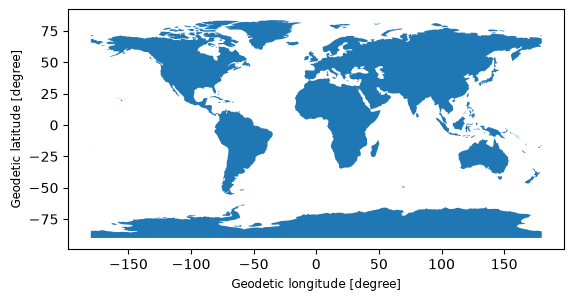

In [20]:
# let's get our basic earth data

path = get_path("naturalearth.land")
world = geopandas.read_file(path)

# and test our libraries loaded

world.plot()

<GeoAxes: title={'center': 'EPSG:4326'}, xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

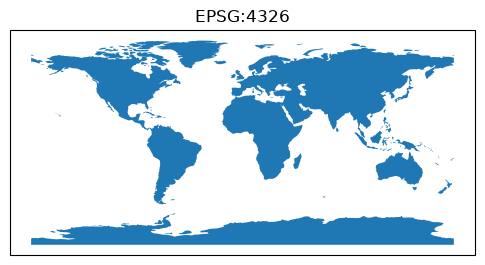

In [37]:
crs = ccrs.epsg("3857")

fig, ax = plt.subplots(subplot_kw={"projection": crs}, figsize=(6, 5))
ax.set(title='EPSG:4326')  # Note: updated to match EPSG:3857 projection
world.plot(ax=ax)

Chapter 1: Dataset

In [9]:
#import dataset

nasa_df = pd.read_csv("../dataset/nasa/final_dataset/nasa_final.csv")

nasa_df

C:\Users\ASUS\AppData\Local\Temp\ipykernel_36100\2621746783.py:3: DtypeWarning: Columns (10: version) have mixed types. Specify dtype option on import or set low_memory=False.
  nasa_df = pd.read_csv("../dataset/nasa/final_dataset/nasa_final.csv")


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-6.32139,138.67276,342.70,0.43,0.46,2026-01-01,352,N20,VIIRS,n,2,286.85,7.55,D
1,-2.74199,132.94307,354.93,0.48,0.64,2026-01-01,353,N20,VIIRS,n,2,289.22,46.30,D
2,-2.72553,132.93201,333.18,0.48,0.65,2026-01-01,353,N20,VIIRS,n,2,288.10,6.35,D
3,-2.73144,132.93283,351.49,0.48,0.65,2026-01-01,353,N20,VIIRS,n,2,288.75,14.95,D
4,-2.74262,132.93880,355.71,0.48,0.65,2026-01-01,353,N20,VIIRS,n,2,288.19,23.54,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1569984,-1.17006,104.32821,354.24,0.42,0.61,2026-10-15,722,SNPP,SNPP,n,2.0NRT,292.17,11.95,D
1569985,-3.48010,102.03445,332.14,0.77,0.77,2026-10-15,739,N20,VIIRS,n,2.0NRT,289.81,6.30,D
1569986,-3.47582,102.03603,335.82,0.77,0.77,2026-10-15,739,N20,VIIRS,n,2.0NRT,289.39,7.82,D
1569987,-1.85875,101.50339,328.40,0.76,0.77,2026-10-15,739,N20,VIIRS,n,2.0NRT,289.90,5.79,D


In [11]:
essential_df = nasa_df[['latitude', 'longitude', 'acq_date', 'acq_time', 'frp']].copy()
essential_df

,latitude,longitude,acq_date,acq_time,frp
0,-6.32139,138.67276,2026-01-01,352,7.55
1,-2.74199,132.94307,2026-01-01,353,46.30
2,-2.72553,132.93201,2026-01-01,353,6.35
3,-2.73144,132.93283,2026-01-01,353,14.95
4,-2.74262,132.93880,2026-01-01,353,23.54
...,...,...,...,...,...
1569984,-1.17006,104.32821,2026-10-15,722,11.95
1569985,-3.48010,102.03445,2026-10-15,739,6.30
1569986,-3.47582,102.03603,2026-10-15,739,7.82
1569987,-1.85875,101.50339,2026-10-15,739,5.79


In [39]:
# now convert latitude, longitude values into point geometry

geo_essential_df = geopandas.GeoDataFrame(
    essential_df, geometry=geopandas.points_from_xy(essential_df.longitude, essential_df.latitude), crs="EPSG:4326"
)

# show top 3 records
geo_essential_df.head(3)

,latitude,longitude,acq_date,acq_time,frp,geometry
0,-6.32139,138.67276,2026-01-01,352,7.55,POINT (138.67276 -6.32139)
1,-2.74199,132.94307,2026-01-01,353,46.30,POINT (132.94307 -2.74199)
2,-2.72553,132.93201,2026-01-01,353,6.35,POINT (132.93201 -2.72553)


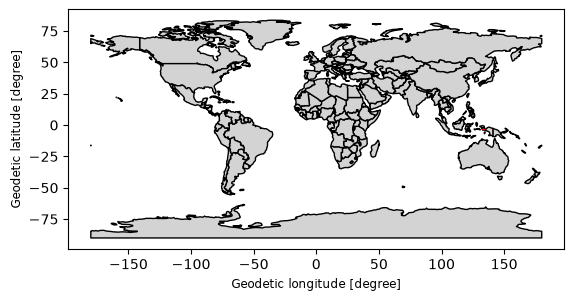

In [65]:
# optional: set outline and fill colors
ax = world.plot(color="lightgrey", edgecolor="black")

# 1. Filter the GeoDataFrame for only rows with exact acq_date and acq_time
filtered_df = geo_essential_df[
    (geo_essential_df['acq_date'] == '2026-01-01') & 
    (geo_essential_df['acq_time'] == 353)
]
# We can now plot our ``GeoDataFrame``.
filtered_df.plot(ax=ax, color="red", markersize=0.1)

plt.show()

In [46]:
# Load the world map directly from the Natural Earth URL (works in GeoPandas 1.0+)
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = geopandas.read_file(url)

# Note: Natural Earth uses 'ADMIN' for country names instead of 'name'. 
# We rename it so your filter code works seamlessly:
world = world.rename(columns={'ADMIN': 'name'})

# Filter for your country (e.g., "France", "Japan", "Canada")
my_country = world[world['name'] == 'Indonesia']

# Get the extent: [xmin, ymin, xmax, ymax]
extent = my_country.total_bounds
print(extent)

[ 95.29302616 -10.35998748 141.03385176   5.47982087]


In [70]:
# 1. Filter the GeoDataFrame for only rows with exact acq_date and acq_time
filtered_df = geo_essential_df[
    (geo_essential_df['acq_date'] == '2026-08-01')
]

filtered_df

,latitude,longitude,acq_date,acq_time,frp,geometry
170008,-8.50705,140.90311,2026-08-01,325,7.30,POINT (140.90311 -8.50705)
170009,-8.10455,139.37332,2026-08-01,325,9.17,POINT (139.37332 -8.10455)
170010,-7.45392,138.35976,2026-08-01,325,11.21,POINT (138.35976 -7.45392)
170011,-8.28035,140.40265,2026-08-01,325,55.35,POINT (140.40265 -8.28035)
170012,-8.69870,140.69739,2026-08-01,325,6.69,POINT (140.69739 -8.6987)
...,...,...,...,...,...,...
174290,4.28458,96.01933,2026-08-01,1930,6.13,POINT (96.01933 4.28458)
174291,2.85807,97.78849,2026-08-01,1932,0.58,POINT (97.78849 2.85807)
174292,0.84366,101.39188,2026-08-01,1932,0.93,POINT (101.39188 0.84366)
174293,2.63479,97.66367,2026-08-01,1932,0.58,POINT (97.66367 2.63479)


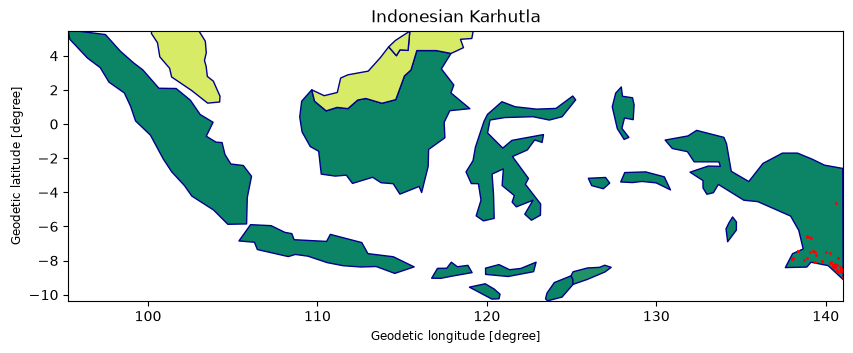

In [98]:
# 1. Filter the GeoDataFrame for only rows with exact acq_date and acq_time
filtered_df = geo_essential_df[
    (geo_essential_df['acq_date'] == '2026-08-01') & 
    (geo_essential_df['acq_time'] == 325)
]

# set our extent
extent = [95.29302616, -10.35998748, 141.03385176, 5.47982087]
ax = world.plot(
    figsize=(10, 10), 
    #color="grey", 
    cmap='summer',
    edgecolor="darkblue")

ax.set_xlim([extent[0],  extent[2]])
ax.set_ylim([extent[1],  extent[3]])

ax.set(title='Indonesian Karhutla')

# We can now plot our ``GeoDataFrame``.
filtered_df.plot(ax=ax, color="red", markersize=1)

plt.show()

CONTEKAN

(40.0, 79.0)

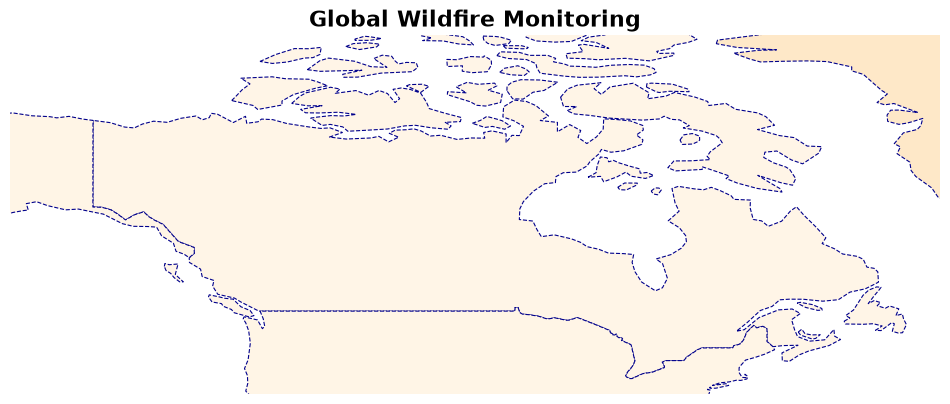

In [ ]:
ax = world.plot(
    cmap='OrRd', 
    figsize=(12, 8),            # Changes the figure width and height (in inches)
    #color="lightblue",          # Fill color of the countries (facecolor)
    edgecolor="darkblue",       # Color of the country borders
    linewidth=0.8,              # Thickness of the country borders
    linestyle="--",             # Border line style ('-', '--', ':', '-.')
    #alpha=0.7                   # Transparency level (0.0 = invisible, 1.0 = solid)
)

ax.set_axis_off()  # Hides the axis box, ticks, and numbers entirely

ax.set_title('Global Wildfire Monitoring', fontsize=16, fontweight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax.set_aspect('equal')

ax.set_xlim([-150, -49])  # Min and max longitude
ax.set_ylim([40, 79])     # Min and max latitude



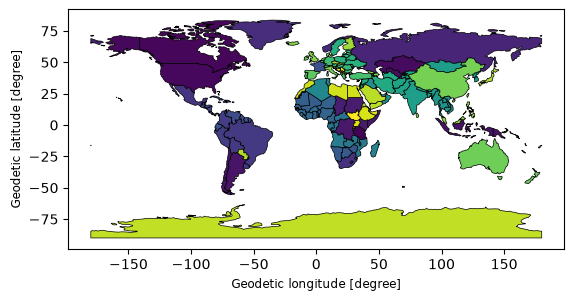

In [ ]:

ax = world.plot(
    column='pop_est',           # The column name containing numerical values
    cmap='OrRd',                # Color map (e.g., 'viridis', 'plasma', 'Blues', 'OrRd')
    legend=True,                # Automatically add a color scale legend
    edgecolor='black',
    linewidth=0.5
)

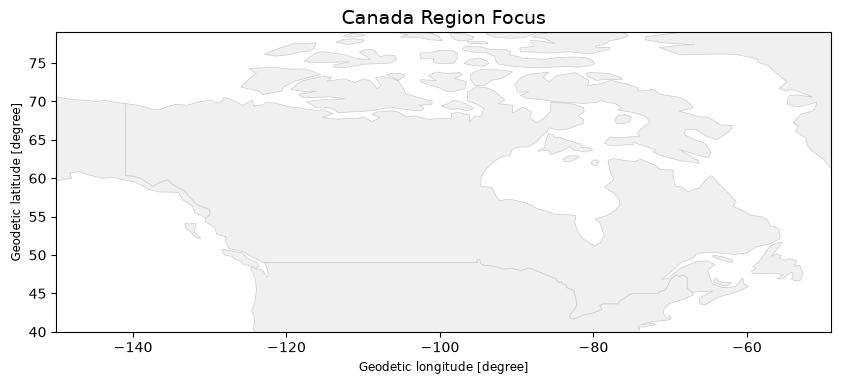

In [75]:

import matplotlib.pyplot as plt

# Initialize and style the map
ax = world.plot(
    figsize=(10, 10),
    color="#f0f0f0",            # Soft light-gray fill
    edgecolor="#cccccc",        # Subtle gray borders
    linewidth=0.5
)

# Apply layout modifications
ax.set_title('Canada Region Focus', fontsize=14)
ax.set_xlim([-150, -49])
ax.set_ylim([40, 79])
ax.set_aspect('equal')
# ax.set_axis_off()           # Uncomment this if you want to hide the outer border/ticks

# Plot your data on top
geo_essential_df.plot(ax=ax, color="red", markersize=1, alpha=0.6)

plt.show()

In [93]:
import matplotlib
list(matplotlib.colormaps)

['magma',
 'inferno',
 'plasma',
 'viridis',
 'cividis',
 'twilight',
 'twilight_shifted',
 'turbo',
 'berlin',
 'managua',
 'vanimo',
 'Blues',
 'BrBG',
 'BuGn',
 'BuPu',
 'CMRmap',
 'GnBu',
 'Greens',
 'Greys',
 'OrRd',
 'Oranges',
 'PRGn',
 'PiYG',
 'PuBu',
 'PuBuGn',
 'PuOr',
 'PuRd',
 'Purples',
 'RdBu',
 'RdGy',
 'RdPu',
 'RdYlBu',
 'RdYlGn',
 'Reds',
 'Spectral',
 'Wistia',
 'YlGn',
 'YlGnBu',
 'YlOrBr',
 'YlOrRd',
 'afmhot',
 'autumn',
 'binary',
 'bone',
 'brg',
 'bwr',
 'cool',
 'coolwarm',
 'copper',
 'cubehelix',
 'flag',
 'gist_earth',
 'gist_gray',
 'gist_heat',
 'gist_ncar',
 'gist_rainbow',
 'gist_stern',
 'gist_yarg',
 'gnuplot',
 'gnuplot2',
 'gray',
 'hot',
 'hsv',
 'jet',
 'nipy_spectral',
 'ocean',
 'pink',
 'prism',
 'rainbow',
 'seismic',
 'spring',
 'summer',
 'terrain',
 'winter',
 'Accent',
 'okabe_ito',
 'Dark2',
 'Paired',
 'Pastel1',
 'Pastel2',
 'Set1',
 'Set2',
 'Set3',
 'tab10',
 'tab20',
 'tab20b',
 'tab20c',
 'grey',
 'gist_grey',
 'gist_yerg',
 'Grays

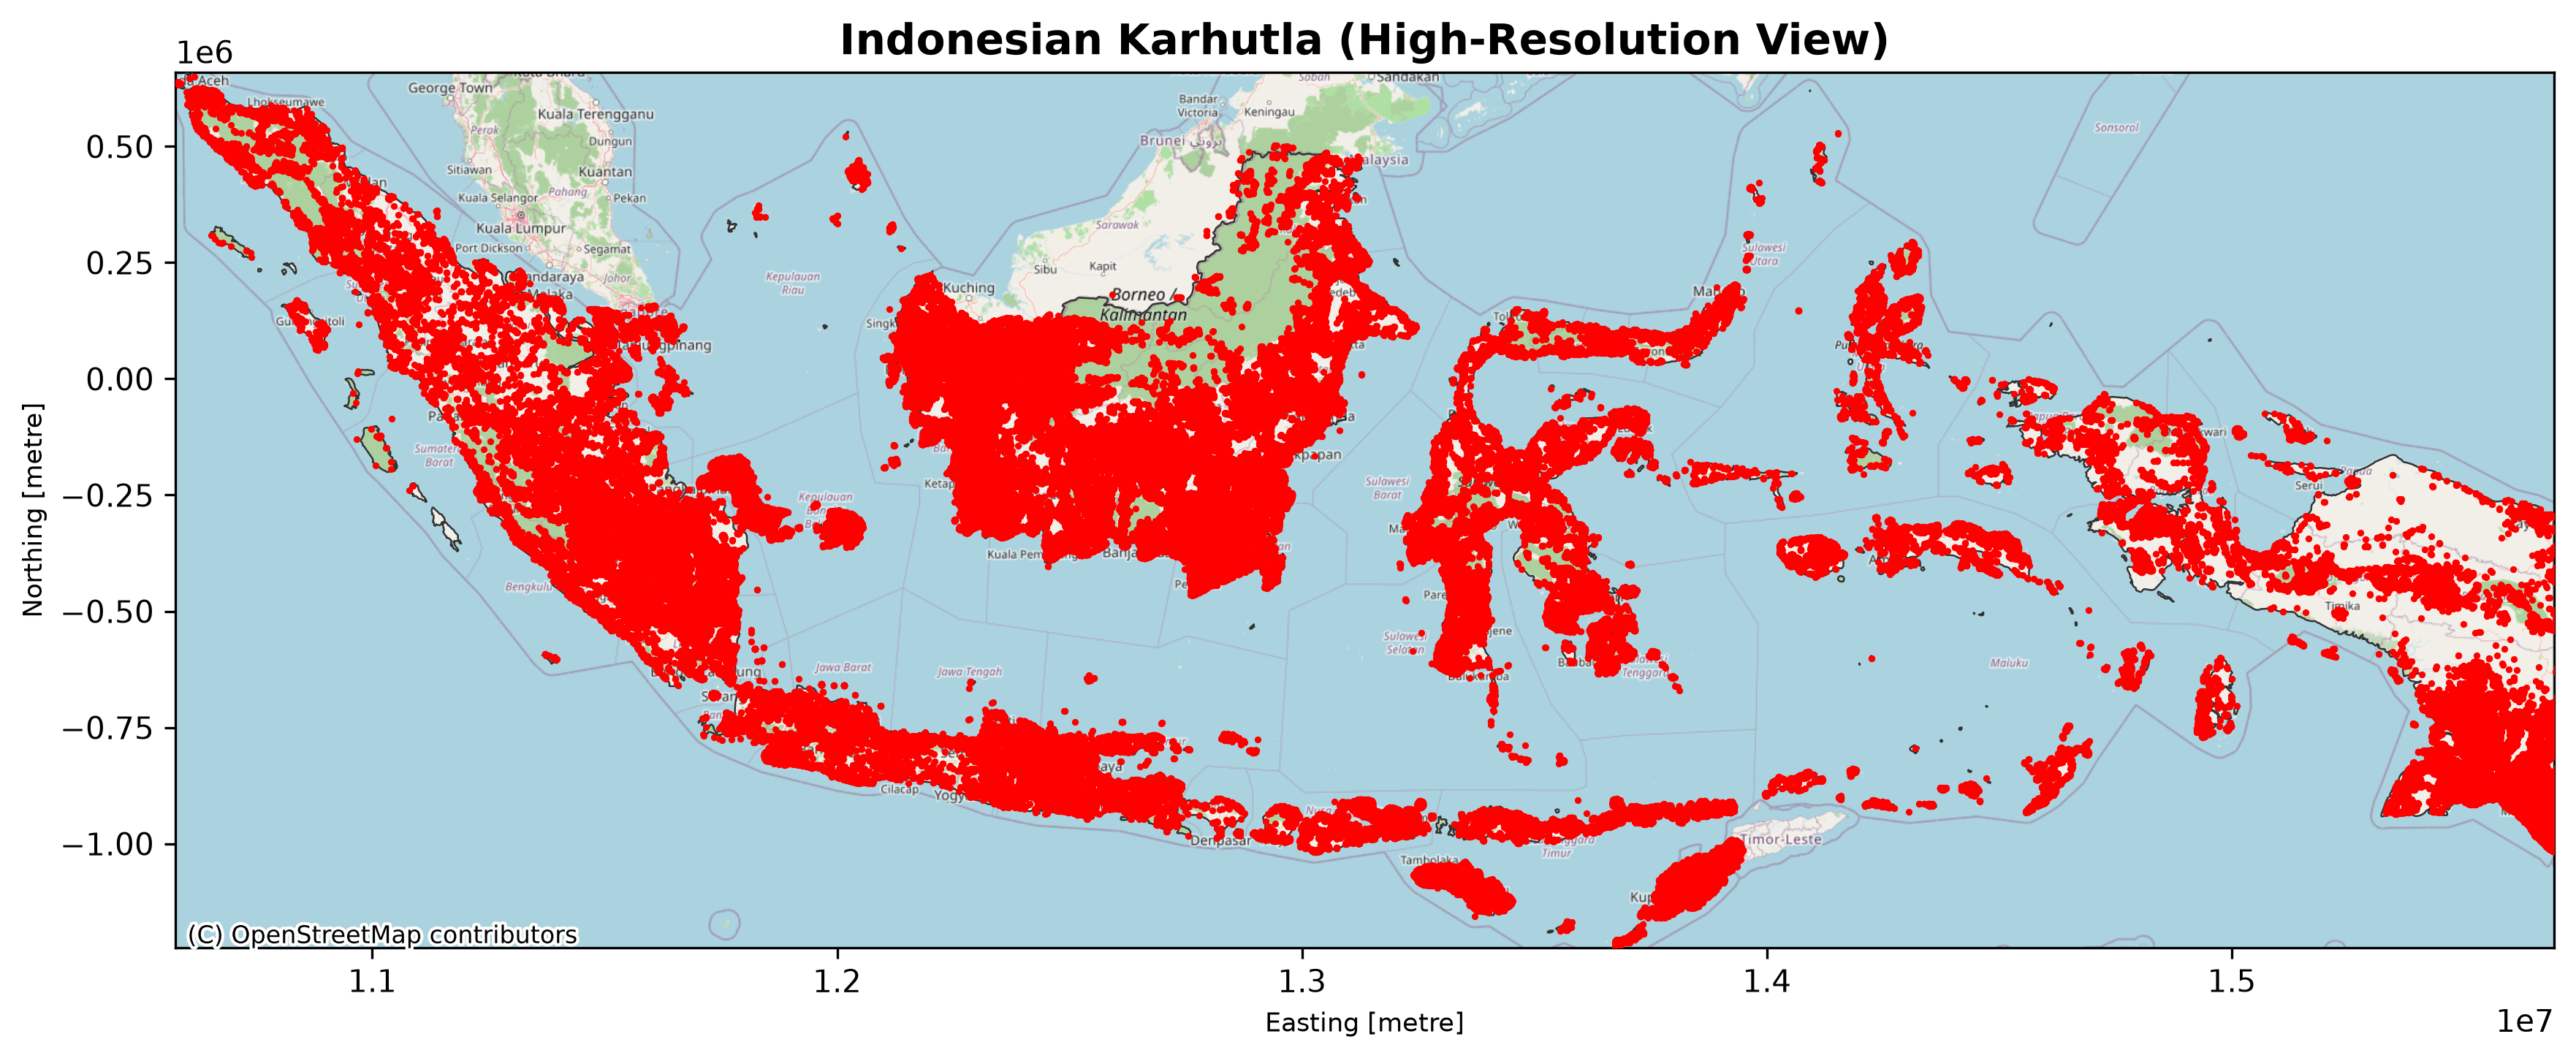

In [104]:
import matplotlib.pyplot as plt
import geopandas as gpd
import contextily as cx

# 1. Use the high-resolution (10m) Natural Earth dataset for smooth coastlines
url = "https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip"
world = gpd.read_file(url).rename(columns={'ADMIN': 'name'})
indonesia = world[world['name'] == 'Indonesia']

# 2. Reproject to Web Mercator (EPSG:3857)
indonesia_wm = indonesia.to_crs(epsg=3857)
geo_essential_df_wm = geo_essential_df.to_crs(epsg=3857)

xmin, ymin, xmax, ymax = indonesia_wm.total_bounds

# 3. Set dpi=300 for crisp, high-definition output
fig, ax = plt.subplots(figsize=(14, 8), dpi=300)

# Plot high-res Indonesia borders
indonesia_wm.plot(ax=ax, color="none", edgecolor="#333333", linewidth=0.6, zorder=3)

# Plot wildfire points
geo_essential_df_wm.plot(ax=ax, color="red", markersize=1.5, zorder=4)

# Force bounds to full country
ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])

# 4. Add OpenStreetMap basemap with a higher zoom level for sharp tiles
cx.add_basemap(
    ax, 
    source=cx.providers.OpenStreetMap.Mapnik, 
    headers={'User-Agent': 'WildfireMappingProject/1.0'},
    zoom=6  # Increase this to 7 if you want even finer detail (may take slightly longer to load)
)

ax.set_title("Indonesian Karhutla (High-Resolution View)", fontsize=14, fontweight='bold')
plt.show()